## K-nearest neighbors

KNN predicts a case from the `k` training cases that look most like it: the share of those neighbors the petitioner won is the model's probability of a petitioner win.

**Same tuning and scoring across all models in project**:
- One-hot preprocessor from `src/preprocess.py` (the one meant for KNN): each category becomes 0/1 columns and `term` is standardized, so distance roughly counts how many case attributes differ.
- **Training terms (1946-2015)** are the neighbors. **Validation terms (2016-2020)** pick the settings through `PredefinedSplit` in `GridSearchCV`, ranked by **ROC AUC**.
- `refit=False`: the chosen setting is refit on training terms only, so the validation score is measured on cases the model never saw.
- The **test terms (2021-2025) are never used here**.

Run with **Restart -> Run All** from the `.venv` (Python 3.13) kernel. Each run appends a row to `results/micah.csv`.

In [9]:
import sys
from pathlib import Path

# make the repo root importable so `src` works from notebooks/micah/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from src import config
from src.data import add_circuit_features, handle_missing, load_data
from src.evaluate import RESULTS_DIR, evaluate
from src.features import add_features
from src.preprocess import make_onehot_preprocessor
from src.split import split_by_term

DATA_PATH = REPO_ROOT / "data" / "SCDB_2026_01_caseCentered_Citation.csv"
OWNER = "micah"
SEED = config.RANDOM_STATE  # 42

In [10]:
# Chart style, matching ian_lr_svm.ipynb: blue = training, orange = validation, gray = context.
BLUE, ORANGE = "#2a78d6", "#eb6834"
GRAY = "#c3c2b7"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID = "#fcfcfb", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "figure.dpi": 110,
})

### 1. Load, add features, split by term, fill blanks
`load_data` -> `add_features` -> `add_circuit_features` -> `split_by_term` -> `handle_missing`. The test part is thrown away on purpose (`_`).

In [11]:
cases = load_data(DATA_PATH)
cases = add_circuit_features(add_features(cases))

X_train, y_train, X_val, y_val, _, _ = split_by_term(cases, config.FEATURE_COLUMNS)

# handle_missing drops nothing here (X only holds feature columns) and fills blanks with -1
X_train = handle_missing(X_train)
X_val = handle_missing(X_val)

assert (len(X_train), len(X_val)) == (7611, 305)

Number of rows loaded: 9,409
Number of rows after decisionType filter: 8,216
Number of rows after partyWinning filter: 8,211
train: 7,611 cases, terms 1946-2015, petitioner win rate 62.8%
  val:   305 cases, terms 2016-2020, petitioner win rate 67.2%
 test:   295 cases, terms 2021-2025, petitioner win rate 69.2%


### 2. Grid search on the validation terms

`PredefinedSplit` uses one fixed fold: rows marked `-1` (training terms) are always the neighbors, rows marked `0` (validation terms) are always scored. The helpers below are the same as in Ian's notebook.

In [12]:
X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])
fold = np.concatenate([np.full(len(X_train), -1), np.zeros(len(X_val), dtype=int)])
validation_fold = PredefinedSplit(fold)

SCORING = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy"}
SCORE_COLUMNS = ["train_roc_auc", "val_roc_auc", "train_bal_acc", "val_bal_acc", "gap_roc_auc"]


def search(model, grid):
    """Try every setting in `grid`: fit on training terms, score on validation terms.

    Returns one row per setting with training and validation scores, best validation ROC AUC first.
    gap_roc_auc = training minus validation (big gap = overfitting).
    """
    pipeline = Pipeline([("prep", make_onehot_preprocessor()), ("model", model)])
    grid_search = GridSearchCV(pipeline, grid, cv=validation_fold, scoring=SCORING,
                               refit=False, return_train_score=True, n_jobs=-1)
    grid_search.fit(X_search, y_search)

    raw = pd.DataFrame(grid_search.cv_results_)
    table = pd.DataFrame(list(raw["params"]))
    table.columns = [name.removeprefix("model__") for name in table.columns]
    table["train_roc_auc"] = raw["mean_train_roc_auc"]
    table["val_roc_auc"] = raw["mean_test_roc_auc"]
    table["train_bal_acc"] = raw["mean_train_balanced_accuracy"]
    table["val_bal_acc"] = raw["mean_test_balanced_accuracy"]
    table["gap_roc_auc"] = table["train_roc_auc"] - table["val_roc_auc"]
    return table.sort_values("val_roc_auc", ascending=False)


def fit_best(model, table):
    """Refit `model` with the top setting in `table` on training terms only."""
    best = table.iloc[0].drop(SCORE_COLUMNS).to_dict()
    best = {name: (value.item() if hasattr(value, "item") else value) for name, value in best.items()}
    pipeline = Pipeline([("prep", make_onehot_preprocessor()), ("model", model.set_params(**best))])
    pipeline.fit(X_train, y_train)
    return pipeline, best


def bootstrap_interval(y_true, y_score, y_pred, n=1000, seed=SEED):
    """95% bootstrap intervals for validation ROC AUC and balanced accuracy."""
    rng = np.random.default_rng(seed)
    y_true, y_score, y_pred = map(np.asarray, (y_true, y_score, y_pred))
    auc, bal = [], []
    for _ in range(n):
        pick = rng.integers(0, len(y_true), len(y_true))
        auc.append(roc_auc_score(y_true[pick], y_score[pick]))
        bal.append(balanced_accuracy_score(y_true[pick], y_pred[pick]))
    return np.percentile(auc, [2.5, 97.5]), np.percentile(bal, [2.5, 97.5])

### 3. KNN settings

- `n_neighbors` (k): how many similar training cases vote. **Small k = complex model** (follows individual cases, easy to overfit); **large k = simple model** (drifts toward the overall win rate). This is the opposite direction from `C`.
- `weights`: `"uniform"` gives every neighbor one vote; `"distance"` gives closer neighbors more say. With `"distance"`, each training case is its own nearest neighbor, so its *training* score is always about 1.0 and its gap says nothing about overfitting; only its validation score counts.

The `val_bal_acc` column uses the default 50% vote cutoff; section 4 explains why the final model uses a different one. ROC AUC, which picks the setting, doesn't depend on the cutoff.

In [13]:
KNN_GRID = {
    "model__n_neighbors": [1, 3, 5, 11, 21, 51, 101, 201, 401],
    "model__weights": ["uniform", "distance"],
}
knn_model = KNeighborsClassifier()
knn_table = search(knn_model, KNN_GRID)
display(knn_table.head(8).round({c: 3 for c in SCORE_COLUMNS}))

,n_neighbors,weights,train_roc_auc,val_roc_auc,train_bal_acc,val_bal_acc,gap_roc_auc
15,201,distance,1.000,0.617,0.999,0.543,0.383
13,101,distance,1.000,0.617,0.999,0.551,0.383
12,101,uniform,0.662,0.616,0.560,0.541,0.045
17,401,distance,1.000,0.615,0.999,0.554,0.385
14,201,uniform,0.649,0.615,0.543,0.553,0.034
16,401,uniform,0.638,0.613,0.535,0.554,0.026
9,21,distance,1.000,0.609,0.999,0.570,0.391
8,21,uniform,0.708,0.607,0.611,0.567,0.101


### 4. Refit the best setting and score it

KNN has no `class_weight`, and 63% of training cases are petitioner wins, so a plain majority vote says "petitioner wins" for almost every case, just like the baselines. Instead, a case is predicted a petitioner win only when the share of winning neighbors is **at least the training win rate (62.8%)**: the KNN version of the `"balanced"` weighting used for logistic regression and the SVMs. The cutoff is fixed from the training terms, not tuned on validation.

Only the chosen cutoff is logged to `results/micah.csv`; the 50% cutoff is printed for comparison.

In [14]:
THRESHOLD = y_train.mean()  # training win rate, about 0.628

knn_pipeline, knn_params = fit_best(knn_model, knn_table)
y_score = knn_pipeline.predict_proba(X_val)[:, 1]  # share of neighbors the petitioner won
y_pred = (y_score >= THRESHOLD).astype(int)

logged_params = {**knn_params, "threshold": round(float(THRESHOLD), 3)}
knn_scores = evaluate("knn", logged_params, y_val, y_pred, y_score, owner=OWNER, split="val")
auc_ci, bal_ci = bootstrap_interval(y_val, y_score, y_pred)
knn_scores["roc_auc_ci"], knn_scores["bal_acc_ci"] = auc_ci, bal_ci

print(f"knn {logged_params}\n"
      f"  accuracy           {knn_scores['accuracy']:.1%}   (baselines 67.2%)\n"
      f"  balanced accuracy  {knn_scores['balanced_accuracy']:.3f}   95% interval {bal_ci[0]:.3f}-{bal_ci[1]:.3f}   (baselines 0.500)\n"
      f"  ROC AUC            {knn_scores['roc_auc']:.3f}   95% interval {auc_ci[0]:.3f}-{auc_ci[1]:.3f}   (baselines 0.500)\n"
      f"  confusion counts   tn={knn_scores['tn']} fp={knn_scores['fp']} fn={knn_scores['fn']} tp={knn_scores['tp']}")

default_pred = (y_score >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, default_pred, labels=[0, 1]).ravel()
print(f"\nfor comparison, 50% cutoff (not logged): balanced accuracy "
      f"{balanced_accuracy_score(y_val, default_pred):.3f}, tn={tn} fp={fp} fn={fn} tp={tp}")

knn {'n_neighbors': 201, 'weights': 'distance', 'threshold': 0.628}
  accuracy           57.0%   (baselines 67.2%)
  balanced accuracy  0.570   95% interval 0.513-0.631   (baselines 0.500)
  ROC AUC            0.616   95% interval 0.549-0.683   (baselines 0.500)
  confusion counts   tn=57 fp=43 fn=88 tp=117

for comparison, 50% cutoff (not logged): balanced accuracy 0.546, tn=15 fp=85 fn=12 tp=193


### 5. Good fit, overfitting or underfitting?

Training and validation ROC AUC as k grows (uniform votes). Distance-weighted validation is shown too; its training line would sit at 1.0, so it is left out.
- **Far left (small k), training high and validation low** -> overfitting.
- **Far right (large k), both sliding toward 0.5** -> underfitting: the vote is close to the overall win rate for every case.
- The best k is where validation peaks.

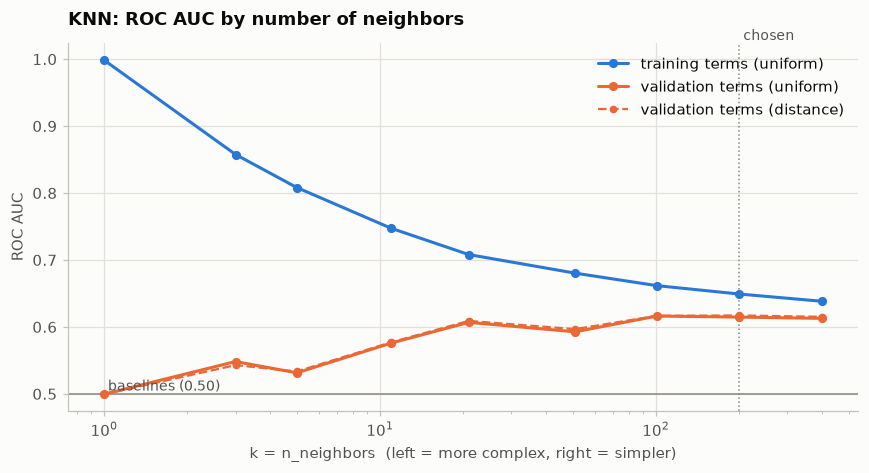

chosen k=201 (distance): train 1.000  val 0.617  gap 0.383
uniform k=1    train 0.999  val 0.500  gap 0.499
uniform k=401  train 0.638  val 0.613  gap 0.026


In [15]:
uniform = knn_table[knn_table["weights"] == "uniform"].sort_values("n_neighbors")
distance = knn_table[knn_table["weights"] == "distance"].sort_values("n_neighbors")

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(uniform["n_neighbors"], uniform["train_roc_auc"], color=BLUE, marker="o", markersize=5, label="training terms (uniform)")
ax.plot(uniform["n_neighbors"], uniform["val_roc_auc"], color=ORANGE, marker="o", markersize=5, label="validation terms (uniform)")
ax.plot(distance["n_neighbors"], distance["val_roc_auc"], color=ORANGE, marker="o", markersize=4,
        linestyle="--", linewidth=1.5, label="validation terms (distance)")
ax.set_xscale("log")
ax.axhline(0.5, color=MUTED, linewidth=1, zorder=0.9)
ax.text(uniform["n_neighbors"].min(), 0.5, " baselines (0.50)", color=INK_2, fontsize=9, va="bottom")
ax.axvline(knn_params["n_neighbors"], color=MUTED, linewidth=1, linestyle=":", zorder=0.9)
ax.text(knn_params["n_neighbors"], 1.0, " chosen", transform=ax.get_xaxis_transform(), color=INK_2, fontsize=9, va="bottom")
ax.set_xlabel("k = n_neighbors  (left = more complex, right = simpler)")
ax.set_ylabel("ROC AUC")
ax.set_title("KNN: ROC AUC by number of neighbors")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

chosen = knn_table.iloc[0]
print(f"chosen k={knn_params['n_neighbors']} ({knn_params['weights']}): "
      f"train {chosen['train_roc_auc']:.3f}  val {chosen['val_roc_auc']:.3f}  gap {chosen['gap_roc_auc']:.3f}")
for k in (uniform["n_neighbors"].min(), uniform["n_neighbors"].max()):
    row = uniform[uniform["n_neighbors"] == k].iloc[0]
    print(f"uniform k={k:<4} train {row['train_roc_auc']:.3f}  val {row['val_roc_auc']:.3f}  gap {row['gap_roc_auc']:.3f}")

### 6. Against the baselines and the team's other models

The latest validation run of each model in `results/`. Every number is on the same 305 validation cases.

In [16]:
runs = pd.concat([pd.read_csv(path) for path in sorted(RESULTS_DIR.glob("*.csv"))], ignore_index=True)
latest = (runs[runs["split"] == "val"]
          .sort_values("timestamp")
          .groupby(["owner", "model"]).tail(1)
          .set_index(["owner", "model"])
          [["accuracy", "balanced_accuracy", "roc_auc", "tn", "fp", "fn", "tp", "params"]]
          .sort_values("roc_auc", ascending=False))
display(latest.round(3))

accuracy  balanced_accuracy  roc_auc  tn  \
owner    model                                                                  
micah    knn                            0.570              0.570    0.616  57   
ian      logistic regression            0.639              0.588    0.615  44   
         linear svm                     0.656              0.583    0.615  37   
         rbf svm                        0.433              0.563    0.612  94   
baseline always petitioner              0.672              0.500    0.500   0   
         previous 10 terms majority     0.672              0.500    0.500   0   

                                      fp   fn   tp  \
owner    model                                       
micah    knn                          43   88  117   
ian      logistic regression          56   54  151   
         linear svm                   63   42  163   
         rbf svm                       6  167   38   
baseline always petitioner           100    0  205   
         previous 10 terms majority  100    0  205   

                                                                                params  
owner    model                                                                          
micah    knn                         {"n_neighbors": 201, "threshold": 0.628, "weig...  
ian      logistic regression                  {"C": 0.001, "class_weight": "balanced"}  
         linear svm                           {"C": 3e-05, "class_weight": "balanced"}  
         rbf svm                     {"C": 0.1, "class_weight": "balanced", "gamma"...  
baseline always petitioner                                                          {}  
         previous 10 terms majority                                     {"window": 10}

### 7. Takeaways

_Numbers from the run on 2026-11-18. If a rerun changes them, update this cell._

**Result (validation terms, 305 cases):** KNN with `k=201`, distance-weighted votes, cutoff 0.628:
- ROC AUC **0.616** (95% interval 0.549-0.683)
- balanced accuracy **0.570** (0.513-0.631)
- accuracy 57.0%

**Against the baselines:** KNN beats both on ROC AUC and balanced accuracy (0.50), and both intervals stay above 0.50. Like Ian's models, it falls short on plain accuracy (67.2%), because the cutoff trades some correct "petitioner wins" calls for correct "petitioner loses" calls. With a 50% cutoff it would call 278 of 305 cases a petitioner win, close to what the baselines do.

**Against the team's models:** KNN's ROC AUC (0.616) ties logistic regression and the linear SVM (0.615). Its balanced accuracy is a little lower (0.570 vs 0.588), but the intervals overlap heavily, so the difference could be luck.

**Fit:**
- `k=1` memorizes the training terms: training ROC AUC 0.999, validation 0.500 (no better than guessing). That is clear overfitting.
- Validation improves steadily up to about `k=100`-`200`, then flattens out. At `k=401` (uniform), training and validation are close (0.638 vs 0.613, gap 0.026), so the model is slightly underfit at that end.
- The top settings are effectively tied: `k=201` distance (0.617), `k=101` distance (0.617) and `k=101` uniform (0.616). Uniform `k=101` has a meaningful gap (0.045). The distance-weighted model's training score is 1.0 by construction, so its gap doesn't show whether it overfits.
- A good model needs about 100+ neighbors, so no small group of past cases decides a new one. That agrees with Ian's finding that these case features carry limited signal.